# Langkah 9 Anggota A — Test Bernoise (SNR 20, 10, 0 dB)

**Tujuan:** menyiapkan data test yang diberi noise, untuk menguji apakah model dan subset fitur hasil SA tetap bekerja di kondisi rekaman yang tidak bersih. Ini bagian tambahan dari *failure experiment*. Anggota C memakai tabel ini di Minggu 12–13; notebook ini **tidak melatih atau mengevaluasi model apa pun**.

**Apa itu SNR?** *Signal-to-noise ratio*: perbandingan daya ucapan dan daya noise, dalam desibel (dB).

| SNR | Arti | Gambaran |
| --- | --- | --- |
| 20 dB | Daya ucapan 100× noise | Ruangan agak ramai, ucapan masih jelas |
| 10 dB | Daya ucapan 10× noise | Noise terdengar jelas |
| 0 dB | Daya ucapan = daya noise | Sangat bising |

**Rancangan**

| Komponen | Pilihan | Alasan |
| --- | --- | --- |
| Data | Hanya test split utama (aktor 21–24, 240 file) | Sesuai Rencana Kerja; train dan validation tetap bersih |
| Jenis noise | `white` (white noise) dan `esc50` (noise ruangan dari ESC-50) | White noise standar dan mudah diulang; ESC-50 mewakili noise nyata |
| Kategori ESC-50 | rain, wind, vacuum_cleaner, washing_machine, engine, keyboard_typing (240 klip) | Bunyi latar yang umum saat orang merekam suara |
| Titik penambahan | Setelah preprocessing (audio sudah di-trim), sebelum ekstraksi fitur | SNR dihitung terhadap bagian ucapan saja, dan efek noise tidak tercampur dengan gagalnya trim |
| Potongan noise | Sama untuk ketiga SNR pada file yang sama (hanya volumenya berbeda) | Perbedaan antar-SNR murni karena keras-pelannya noise |
| Normalisasi | Versi `none` dan `peak`, sama seperti tabel bersih | Versi yang dipilih B dari baseline tinggal dipakai |
| Seed | 2026 | Hasil bisa diulang persis |

**Input dan output**

| Jenis | Lokasi (di `MyDrive/project07/`) | Keterangan |
| --- | --- | --- |
| Input | `data/processed/ravdess_16k_trim/` | Audio test hasil langkah 4 |
| Input | `data/splits.json`, `data/features/features_none.csv` | Daftar aktor test dan fitur bersih |
| Input | `src/preprocess.py`, `src/features.py`, `config.json` | Pipeline yang sama dengan langkah 5 |
| Unduhan | `data/raw/esc50/` | 240 klip ESC-50 (±105 MB, tidak di-push) |
| Output | `src/noise.py` | Modul penambahan noise |
| Output | `data/features/noisy/test_noisy_{jenis}_{snr}db_{versi}.csv` | 12 tabel: 2 jenis × 3 SNR × 2 versi, masing-masing 240 baris |
| Output | `data/features/noisy/noisy_log.csv`, `noisy_meta.json` | Sumber noise, SNR terukur, config_hash |
| Output | `figures/noisy/` | 2 grafik + `noisy_summary.txt` |
| Output | `docs/README_langkah9_test_bernoise.md` | Dokumentasi standar |

**Prasyarat:** langkah 4, 5, dan 7 selesai. **Perkiraan waktu:** 20–35 menit (Sel 6 paling lama).

**Cara pakai:** jalankan sel berurutan dengan `Shift + Enter`.

## Sel 1 — Persiapan dan cek prasyarat

In [1]:
import os
import sys
import json
import time
import hashlib
import importlib
import urllib.request
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from datetime import datetime

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/project07'
except ImportError:
    BASE_DIR = os.path.abspath('project07')

DATA_DIR = os.path.join(BASE_DIR, 'data')
PROC_DIR = os.path.join(DATA_DIR, 'processed', 'ravdess_16k_trim')
FEAT_DIR = os.path.join(DATA_DIR, 'features')
NOISY_DIR = os.path.join(FEAT_DIR, 'noisy')
ESC_DIR = os.path.join(DATA_DIR, 'raw', 'esc50')
SRC_DIR = os.path.join(BASE_DIR, 'src')
FIG_DIR = os.path.join(BASE_DIR, 'figures', 'noisy')
DOC_DIR = os.path.join(BASE_DIR, 'docs')
CONFIG_PATH = os.path.join(BASE_DIR, 'config.json')
MODULE_PATH = os.path.join(SRC_DIR, 'noise.py')
for d in [NOISY_DIR, ESC_DIR, FIG_DIR, DOC_DIR]:
    os.makedirs(d, exist_ok=True)

wajib = [CONFIG_PATH, os.path.join(SRC_DIR, 'preprocess.py'), os.path.join(SRC_DIR, 'features.py'),
         os.path.join(DATA_DIR, 'splits.json'), os.path.join(FEAT_DIR, 'features_none.csv'), PROC_DIR]
hilang = [p for p in wajib if not os.path.exists(p)]
if hilang:
    raise FileNotFoundError('Prasyarat tidak ditemukan:\n' + '\n'.join(hilang))

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
import preprocess as pp
import features as ft
import data_splits as ds

with open(CONFIG_PATH, encoding='utf-8') as f:
    CONFIG = json.load(f)
PRE = CONFIG['preprocessing']
FC = {k: CONFIG['features'][k] for k in ['sr', 'n_fft', 'hop_length', 'n_mfcc', 'n_mels', 'delta_width', 'f0_fmin',
                                          'f0_fmax', 'f0_frame_length', 'rolloff_percent', 'contrast_fmin', 'contrast_n_bands']}
SR = FC['sr']
S = ds.load_splits(BASE_DIR)
fn = pd.read_csv(os.path.join(FEAT_DIR, 'features_none.csv'))
names = pd.read_csv(os.path.join(FEAT_DIR, 'feature_names.csv'))
INFO_COLS = ['file', 'actor', 'gender', 'emotion', 'intensity']
test_rows = fn[fn['actor'].isin(S['test'])].reset_index(drop=True)
N_CPU = os.cpu_count() or 1

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.titlecolor': '#0b0b0b', 'font.size': 10})

print('BASE_DIR   :', BASE_DIR)
print('Aktor test :', S['test'], '->', len(test_rows), 'file')
print('config_hash fitur:', CONFIG['features']['config_hash'], '| splits:', CONFIG.get('splits', {}).get('config_hash'))
print('CPU        :', N_CPU)

Mounted at /content/drive
BASE_DIR   : /content/drive/MyDrive/project07
Aktor test : [21, 22, 23, 24] -> 240 file
config_hash fitur: 0c3114fc78 | splits: 04ad9a2f5b
CPU        : 2


## Sel 2 — Parameter dan `config.json`

In [2]:
NOISY_CONFIG = {
    'snr_db': [20, 10, 0],
    'noise_types': ['white', 'esc50'],
    'esc50_categories': ['rain', 'wind', 'vacuum_cleaner', 'washing_machine', 'engine', 'keyboard_typing'],
    'esc50_source': 'https://github.com/karolpiczak/ESC-50 (CC BY-NC 3.0, Piczak 2015)',
    'esc50_silence_top_db': 40,
    'esc50_min_seconds': 1.0,
    'mix_point': 'setelah preprocessing (trim), sebelum ekstraksi fitur',
    'snr_reference': 'daya ucapan hasil trim',
    'same_noise_segment_across_snr': True,
    'seed': 2026,
    'split': 'test split utama',
}
NOISY_HASH = hashlib.md5(json.dumps({**NOISY_CONFIG, 'features': CONFIG['features']['config_hash'],
                                     'test_actors': S['test']}, sort_keys=True).encode()).hexdigest()[:10]
CONFIG['noisy_test'] = {**NOISY_CONFIG, 'features_hash': CONFIG['features']['config_hash'],
                        'version': '1.0', 'config_hash': NOISY_HASH,
                        'updated': datetime.now().strftime('%Y-%m-%d'), 'owner': 'Anggota A'}
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(CONFIG, f, indent=2, ensure_ascii=False)
print('config_hash noisy_test:', NOISY_HASH)
print('Tersimpan: config.json (bagian noisy_test)')

config_hash noisy_test: dcf3a82fad
Tersimpan: config.json (bagian noisy_test)


## Sel 3 — Unduh klip noise ESC-50

Hanya 240 klip dari 6 kategori yang diunduh, bukan seluruh dataset (600 MB). Klip yang sudah ada tidak diunduh ulang, jadi sel ini aman dijalankan lagi jika koneksi terputus.

In [3]:
ESC_RAW = 'https://raw.githubusercontent.com/karolpiczak/ESC-50/master'
meta_path = os.path.join(ESC_DIR, 'esc50.csv')
if not os.path.exists(meta_path):
    urllib.request.urlretrieve(ESC_RAW + '/meta/esc50.csv', meta_path)
esc_meta = pd.read_csv(meta_path)
esc_sel = esc_meta[esc_meta['category'].isin(NOISY_CONFIG['esc50_categories'])].sort_values('filename').reset_index(drop=True)
print('Klip terpilih:', len(esc_sel), '|', esc_sel['category'].value_counts().to_dict())

gagal_unduh = []
mulai = time.time()
for i, fname in enumerate(esc_sel['filename'], start=1):
    out = os.path.join(ESC_DIR, fname)
    if os.path.exists(out) and os.path.getsize(out) > 1000:
        continue
    for coba in range(3):
        try:
            urllib.request.urlretrieve(f'{ESC_RAW}/audio/{fname}', out)
            break
        except Exception as e:
            if coba == 2:
                gagal_unduh.append((fname, str(e)))
            time.sleep(2)
    if i % 40 == 0:
        print(f'  {i}/{len(esc_sel)} klip | {time.time() - mulai:.0f} detik')
print('Gagal diunduh:', len(gagal_unduh))
if gagal_unduh:
    print('Jalankan ulang sel ini untuk mencoba lagi. Contoh:', gagal_unduh[:3])

Klip terpilih: 240 | {'vacuum_cleaner': 40, 'keyboard_typing': 40, 'wind': 40, 'rain': 40, 'engine': 40, 'washing_machine': 40}
  40/240 klip | 10 detik
  80/240 klip | 20 detik
  120/240 klip | 31 detik
  160/240 klip | 42 detik
  200/240 klip | 50 detik
  240/240 klip | 60 detik
Gagal diunduh: 0


## Sel 4 — Tulis dan uji modul `src/noise.py`

In [4]:
%%writefile {MODULE_PATH}
"""
noise.py — Penambahan noise pada SNR tertentu untuk Proyek 07 (test bernoise).

Penanggung jawab : Anggota A
Versi            : 1.0

SNR (signal-to-noise ratio) dihitung terhadap daya ucapan yang sudah di-trim:
    SNR_dB = 10 * log10(P_ucapan / P_noise)
Semakin kecil SNR, semakin keras noise-nya. Pada 0 dB, daya noise sama dengan daya ucapan.

Contoh:
    import noise as nz
    rng = np.random.default_rng(0)
    seg = nz.white_noise(len(y), rng)
    y_mix, gain = nz.mix_at_snr(y, seg, snr_db=10)
    nz.measure_snr(y, y_mix)   # ~10.0
"""
import numpy as np
import librosa

NOISE_VERSION = '1.0'


def signal_power(y):
    """Daya rata-rata sinyal (mean kuadrat), dihitung dalam float64."""
    y = np.asarray(y, dtype=np.float64)
    return float(np.mean(y ** 2)) if y.size else 0.0


def white_noise(n, rng):
    """White noise Gaussian sepanjang n sampel (float32)."""
    return rng.standard_normal(n).astype(np.float32)


def fit_length(noise, n, offset=0):
    """Ambil potongan noise sepanjang n mulai dari offset; diulang (tile) jika noise lebih pendek."""
    noise = np.asarray(noise, dtype=np.float32)
    if noise.size == 0:
        raise ValueError('noise kosong')
    reps = int(np.ceil((offset % noise.size + n) / noise.size)) + 1
    long = np.tile(noise, reps)
    start = offset % noise.size
    return long[start:start + n]


def mix_at_snr(speech, noise_seg, snr_db):
    """Campur ucapan dan noise sehingga SNR = snr_db. Kembalikan (campuran float32, faktor pengali noise)."""
    speech = np.asarray(speech, dtype=np.float32)
    noise_seg = np.asarray(noise_seg, dtype=np.float32)
    if noise_seg.shape != speech.shape:
        raise ValueError('panjang noise harus sama dengan ucapan')
    ps, pn = signal_power(speech), signal_power(noise_seg)
    if ps == 0 or pn == 0:
        raise ValueError('daya ucapan atau noise nol')
    gain = float(np.sqrt(ps / (pn * 10.0 ** (snr_db / 10.0))))
    return (speech + np.float32(gain) * noise_seg).astype(np.float32), gain


def measure_snr(speech, mixed):
    """SNR terukur (dB) dari ucapan bersih dan hasil campuran."""
    speech = np.asarray(speech, dtype=np.float64)
    noise = np.asarray(mixed, dtype=np.float64) - speech
    return float(10.0 * np.log10(signal_power(speech) / signal_power(noise)))


def clean_noise_clip(y, top_db=40, min_samples=16000):
    """Buang bagian hening di klip noise (klip ESC-50 kadang diberi padding hening).

    Kembalikan klip tanpa hening, atau None jika sisa bunyinya lebih pendek dari min_samples.
    """
    y = np.asarray(y, dtype=np.float32)
    if y.size == 0 or float(np.max(np.abs(y))) == 0.0:
        return None
    iv = librosa.effects.split(y, top_db=top_db)
    if len(iv) == 0:
        return None
    out = np.concatenate([y[s:e] for s, e in iv])
    return out if out.size >= min_samples else None


Writing /content/drive/MyDrive/project07/src/noise.py


In [5]:
import noise as nz
importlib.reload(nz)

uji = []
def u(nama, kondisi, detail=''):
    uji.append(f"[{'OK' if kondisi else 'CEK'}] {nama}" + (f' — {detail}' if detail else ''))

rng = np.random.default_rng(0)
t = np.arange(SR) / SR
y_uji = (0.1 * np.sin(2 * np.pi * 180 * t)).astype(np.float32)
for snr in NOISY_CONFIG['snr_db']:
    m, _ = nz.mix_at_snr(y_uji, nz.white_noise(len(y_uji), rng), snr)
    u(f'SNR terukur = target ({snr} dB)', abs(nz.measure_snr(y_uji, m) - snr) < 0.01, f'{nz.measure_snr(y_uji, m):.4f} dB')
seg = np.arange(10, dtype=np.float32)
u('fit_length mengulang noise pendek dengan benar', np.array_equal(nz.fit_length(seg, 25, 7), np.tile(seg, 4)[7:32]))
a = nz.white_noise(1000, np.random.default_rng(5))
b = nz.white_noise(1000, np.random.default_rng(5))
u('White noise bisa diulang dengan seed yang sama', np.array_equal(a, b))
klip = np.concatenate([np.zeros(SR, np.float32), 0.1 * np.ones(SR, np.float32) * np.sign(np.sin(2 * np.pi * 50 * t)).astype(np.float32)])
u('clean_noise_clip membuang hening', len(nz.clean_noise_clip(klip, 40, SR // 2)) < len(klip))
for x in uji:
    print(x)

[OK] SNR terukur = target (20 dB) — 20.0000 dB
[OK] SNR terukur = target (10 dB) — 10.0000 dB
[OK] SNR terukur = target (0 dB) — 0.0000 dB
[OK] fit_length mengulang noise pendek dengan benar
[OK] White noise bisa diulang dengan seed yang sama
[OK] clean_noise_clip membuang hening


## Sel 5 — Siapkan sumber noise

Klip ESC-50 dimuat, dijadikan mono 16 kHz, lalu bagian heningnya dibuang (sebagian klip diberi padding hening). Klip yang sisa bunyinya kurang dari 1 detik tidak dipakai.

Untuk setiap file test dan jenis noise, generator acak dengan seed `(2026, nomor file, jenis noise)` memilih klip dan posisi awal potongan noise. Potongan yang sama dipakai untuk ketiga SNR.

In [6]:
ESC = {}
for _, r in esc_sel.iterrows():
    p = os.path.join(ESC_DIR, r['filename'])
    if not os.path.exists(p):
        continue
    y, _ = librosa.load(p, sr=SR, mono=True)
    c = nz.clean_noise_clip(y, NOISY_CONFIG['esc50_silence_top_db'], int(NOISY_CONFIG['esc50_min_seconds'] * SR))
    if c is not None:
        ESC[r['filename']] = c
ESC_NAMES = sorted(ESC)
print(f'Klip ESC-50 terpakai: {len(ESC_NAMES)} dari {len(esc_sel)}')
print('Per kategori:', esc_sel[esc_sel['filename'].isin(ESC_NAMES)]['category'].value_counts().to_dict())

def rencana_noise(i_file, jenis, n):
    # Tentukan sumber dan posisi noise untuk satu file secara deterministik.
    k = NOISY_CONFIG['noise_types'].index(jenis)
    rng = np.random.default_rng([NOISY_CONFIG['seed'], i_file, k])
    if jenis == 'white':
        return 'white', 0, nz.white_noise(n, rng)
    nama = ESC_NAMES[int(rng.integers(len(ESC_NAMES)))]
    offset = int(rng.integers(len(ESC[nama])))
    return nama, offset, nz.fit_length(ESC[nama], n, offset)

Klip ESC-50 terpakai: 240 dari 240
Per kategori: {'vacuum_cleaner': 40, 'keyboard_typing': 40, 'wind': 40, 'rain': 40, 'engine': 40, 'washing_machine': 40}


## Sel 6 — Buat 12 tabel fitur test bernoise

Untuk setiap file test (240) dan jenis noise (2): ambil potongan noise, campur pada SNR 20, 10, dan 0 dB, lalu ekstrak 90 fitur versi `none` dan `peak`, persis seperti langkah 5.

Hasil disimpan per jenis noise. Jika Colab terputus, jalankan ulang Sel 1–5 lalu sel ini; jenis noise yang sudah selesai (dengan config_hash sama) tidak diulang. Butuh sekitar 15–30 menit.

In [7]:
SNRS = NOISY_CONFIG['snr_db']
def out_path(jenis, snr, versi):
    return os.path.join(NOISY_DIR, f'test_noisy_{jenis}_{snr}db_{versi}.csv')

def proses_satu(arg):
    i_file, f, jenis = arg
    y, _ = sf.read(os.path.join(PROC_DIR, f), dtype='float32')
    sumber, offset, seg = rencana_noise(i_file, jenis, len(y))
    hasil = []
    for snr in SNRS:
        y_mix, gain = nz.mix_at_snr(y, seg, snr)
        f0 = ft.extract_f0_features(y_mix, FC)
        x_none = ft.extract_features(y_mix, FC, f0_feats=f0)
        x_peak = ft.extract_features(pp.normalize(y_mix, 'peak', PRE['peak_target']), FC, f0_feats=f0)
        hasil.append({'snr': snr, 'none': x_none, 'peak': x_peak,
                      'log': {'file': f, 'noise_type': jenis, 'noise_source': sumber, 'offset': offset,
                              'snr_target': snr, 'snr_measured': round(nz.measure_snr(y, y_mix), 4),
                              'gain': gain, 'peak_mix': float(np.max(np.abs(y_mix)))}})
    return hasil

def sudah_ada(jenis):
    p = os.path.join(NOISY_DIR, f'_done_{jenis}.json')
    if not os.path.exists(p) or not all(os.path.exists(out_path(jenis, s, v)) for s in SNRS for v in ['none', 'peak']):
        return False
    with open(p) as fh:
        return json.load(fh).get('config_hash') == NOISY_HASH

LOGS = []
for jenis in NOISY_CONFIG['noise_types']:
    log_j = os.path.join(NOISY_DIR, f'_log_{jenis}.csv')
    if sudah_ada(jenis):
        print(f'{jenis}: sudah selesai dengan parameter sama, dilewati.')
        LOGS.append(pd.read_csv(log_j))
        continue
    mulai = time.time()
    tugas = [(i, f, jenis) for i, f in enumerate(test_rows['file'])]
    ctx = mp.get_context('fork')
    with ProcessPoolExecutor(max_workers=N_CPU, mp_context=ctx) as ex:
        semua = []
        for k, h in enumerate(ex.map(proses_satu, tugas, chunksize=4), start=1):
            semua.append(h)
            if k % 40 == 0 or k == len(tugas):
                print(f'  {jenis}: {k}/{len(tugas)} file | {(time.time() - mulai) / 60:.1f} menit', flush=True)
    for j, snr in enumerate(SNRS):
        for versi in ['none', 'peak']:
            X = pd.DataFrame([h[j][versi] for h in semua], columns=ft.FEATURE_NAMES)
            pd.concat([test_rows[INFO_COLS], X], axis=1).to_csv(out_path(jenis, snr, versi), index=False)
    lg = pd.DataFrame([h[j]['log'] for h in semua for j in range(len(SNRS))])
    lg.to_csv(log_j, index=False)
    LOGS.append(lg)
    with open(os.path.join(NOISY_DIR, f'_done_{jenis}.json'), 'w') as fh:
        json.dump({'config_hash': NOISY_HASH}, fh)
    print(f'{jenis}: selesai dalam {(time.time() - mulai) / 60:.1f} menit')

LOG = pd.concat(LOGS, ignore_index=True)
LOG.to_csv(os.path.join(NOISY_DIR, 'noisy_log.csv'), index=False)
with open(os.path.join(NOISY_DIR, 'noisy_meta.json'), 'w', encoding='utf-8') as fh:
    json.dump({'config_hash': NOISY_HASH, 'features_hash': CONFIG['features']['config_hash'],
               'created': datetime.now().strftime('%Y-%m-%d %H:%M'), 'n_test_files': len(test_rows),
               'esc50_clips_used': len(ESC_NAMES), 'files': sorted(os.path.basename(out_path(j, s, v))
               for j in NOISY_CONFIG['noise_types'] for s in SNRS for v in ['none', 'peak'])}, fh, indent=2)
print('Tersimpan: 12 tabel, noisy_log.csv, noisy_meta.json di', NOISY_DIR)

  white: 40/240 file | 1.5 menit
  white: 80/240 file | 2.8 menit
  white: 120/240 file | 4.1 menit
  white: 160/240 file | 5.2 menit
  white: 200/240 file | 6.5 menit
  white: 240/240 file | 7.8 menit
white: selesai dalam 7.8 menit
  esc50: 40/240 file | 1.4 menit
  esc50: 80/240 file | 2.6 menit
  esc50: 120/240 file | 3.9 menit
  esc50: 160/240 file | 5.0 menit
  esc50: 200/240 file | 6.2 menit
  esc50: 240/240 file | 7.5 menit
esc50: selesai dalam 7.5 menit
Tersimpan: 12 tabel, noisy_log.csv, noisy_meta.json di /content/drive/MyDrive/project07/data/features/noisy


## Sel 7 — Verifikasi

In [8]:
laporan = []
def cek(nama, kondisi, detail=''):
    laporan.append(f"[{'OK' if kondisi else 'CEK'}] {nama}" + (f' — {detail}' if detail else ''))

T = {(j, s, v): pd.read_csv(out_path(j, s, v)) for j in NOISY_CONFIG['noise_types'] for s in SNRS for v in ['none', 'peak']}
cek('12 tabel ada, masing-masing 240 baris dengan kolom sama seperti tabel bersih',
    len(T) == 12 and all(len(d) == len(test_rows) and list(d.columns) == list(fn.columns) for d in T.values()),
    f'{len(T)} tabel')
cek('Hanya aktor test (21-24), urutan file dan kolom info sama dengan tabel bersih',
    all(d[INFO_COLS].astype(str).equals(test_rows[INFO_COLS].astype(str)) for d in T.values()))
F = list(names['name'])
cek('Tidak ada NaN atau nilai tak hingga', all(np.isfinite(d[F].to_numpy(float)).all() for d in T.values()))
sel = (LOG['snr_measured'] - LOG['snr_target']).abs()
cek('SNR terukur = target (selisih < 0,05 dB) untuk semua campuran', bool((sel < 0.05).all()) and len(LOG) == len(test_rows) * 6,
    f'{len(LOG)} campuran, selisih maks {sel.max():.4f} dB')
sama = LOG.groupby(['file', 'noise_type'])[['noise_source', 'offset']].nunique()
cek('Potongan noise sama untuk ketiga SNR pada setiap file', bool((sama == 1).all().all()))
non_energi = names.loc[~names['scale_dependent'].astype(bool), 'name'].tolist()
A_ne = np.vstack([T[(j, s, 'none')][non_energi].to_numpy(float) for j in NOISY_CONFIG['noise_types'] for s in SNRS])
B_ne = np.vstack([T[(j, s, 'peak')][non_energi].to_numpy(float) for j in NOISY_CONFIG['noise_types'] for s in SNRS])
dekat = np.isclose(A_ne, B_ne, rtol=1e-3, atol=1e-4)
rel_maks = float((np.abs(A_ne - B_ne) / np.maximum(np.abs(A_ne), 1e-4)).max())
cek('87 fitur non-energi sama antara versi none dan peak (selisih hanya pembulatan float32)',
    dekat.mean() >= 0.999 and np.allclose(A_ne, B_ne, rtol=1e-2, atol=1e-3),
    f'{dekat.mean():.4%} nilai dalam toleransi 0,1%; selisih relatif maks {rel_maks:.2%}')
rng = np.random.default_rng(1)
contoh = [(int(i), j) for i, j in zip(rng.choice(len(test_rows), 3, replace=False), ['white', 'esc50', 'esc50'])]
ulang_ok = True
for i, j in contoh:
    h = proses_satu((i, test_rows['file'][i], j))
    for k, s in enumerate(SNRS):
        ulang_ok &= np.allclose(h[k]['none'], T[(j, s, 'none')].loc[i, F].to_numpy(float), rtol=1e-6, atol=1e-9)
cek('Ekstraksi ulang 3 contoh acak = hasil tersimpan', bool(ulang_ok))

# Distorsi fitur: selisih terhadap fitur bersih, dibagi simpangan baku fitur di data train
train_std = fn[fn['actor'].isin(S['train'])][F].std().replace(0, np.nan)
clean = test_rows[F]
DIST = {}
for j in NOISY_CONFIG['noise_types']:
    for s in SNRS:
        DIST[(j, s)] = ((T[(j, s, 'none')][F] - clean).abs() / train_std).mean()
mono = all(DIST[(j, 20)].mean() < DIST[(j, 10)].mean() < DIST[(j, 0)].mean() for j in NOISY_CONFIG['noise_types'])
cek('Distorsi fitur makin besar saat SNR makin kecil (20 < 10 < 0 dB)', mono,
    '; '.join(f"{j}: " + ' / '.join(f'{DIST[(j, s)].mean():.2f}' for s in SNRS) for j in NOISY_CONFIG['noise_types']))
cek('Klip ESC-50 cukup (minimal 200 klip terpakai, 6 kategori)', len(ESC_NAMES) >= 200
    and esc_sel[esc_sel['filename'].isin(ESC_NAMES)]['category'].nunique() == 6, f'{len(ESC_NAMES)} klip')

for x in laporan:
    print(x)
n_ok = sum(x.startswith('[OK') for x in laporan)
print(f'\n{n_ok}/{len(laporan)} OK')

unv = {f'{j} {s} dB': int((T[(j, s, 'none')]['voiced_ratio'] == 0).sum()) for j in NOISY_CONFIG['noise_types'] for s in SNRS}
print('\nFile tanpa frame bersuara (bersih: %d):' % int((test_rows['voiced_ratio'] == 0).sum()), unv)
print('Puncak campuran tertinggi:', round(LOG['peak_mix'].max(), 3), '(di atas 1 tidak masalah karena disimpan sebagai angka float)')

[OK] 12 tabel ada, masing-masing 240 baris dengan kolom sama seperti tabel bersih — 12 tabel
[OK] Hanya aktor test (21-24), urutan file dan kolom info sama dengan tabel bersih
[OK] Tidak ada NaN atau nilai tak hingga
[OK] SNR terukur = target (selisih < 0,05 dB) untuk semua campuran — 1440 campuran, selisih maks 0.0000 dB
[OK] Potongan noise sama untuk ketiga SNR pada setiap file
[OK] 87 fitur non-energi sama antara versi none dan peak (selisih hanya pembulatan float32) — 99.9992% nilai dalam toleransi 0,1%; selisih relatif maks 0.19%
[OK] Ekstraksi ulang 3 contoh acak = hasil tersimpan
[OK] Distorsi fitur makin besar saat SNR makin kecil (20 < 10 < 0 dB) — white: 1.20 / 1.90 / 2.67; esc50: 0.56 / 0.95 / 1.48
[OK] Klip ESC-50 cukup (minimal 200 klip terpakai, 6 kategori) — 240 klip

9/9 OK

File tanpa frame bersuara (bersih: 2): {'white 20 dB': 2, 'white 10 dB': 14, 'white 0 dB': 134, 'esc50 20 dB': 1, 'esc50 10 dB': 11, 'esc50 0 dB': 64}
Puncak campuran tertinggi: 3.681 (di atas 1 tid

**Catatan:** notebook ini hanya membandingkan **fitur** sebelum dan sesudah diberi noise, tanpa label emosi dan tanpa model. Jadi data test tidak "terpakai" untuk memilih apa pun. Evaluasi model di data ini tetap dilakukan Anggota C.

## Sel 8 — Grafik

- `noisy_01`: mel-spectrogram satu file test dalam kondisi bersih dan ketiga SNR, untuk kedua jenis noise.
- `noisy_02`: seberapa besar fitur setiap kelompok bergeser karena noise. Angka 1,0 berarti rata-rata fitur bergeser sebesar satu simpangan baku data train.

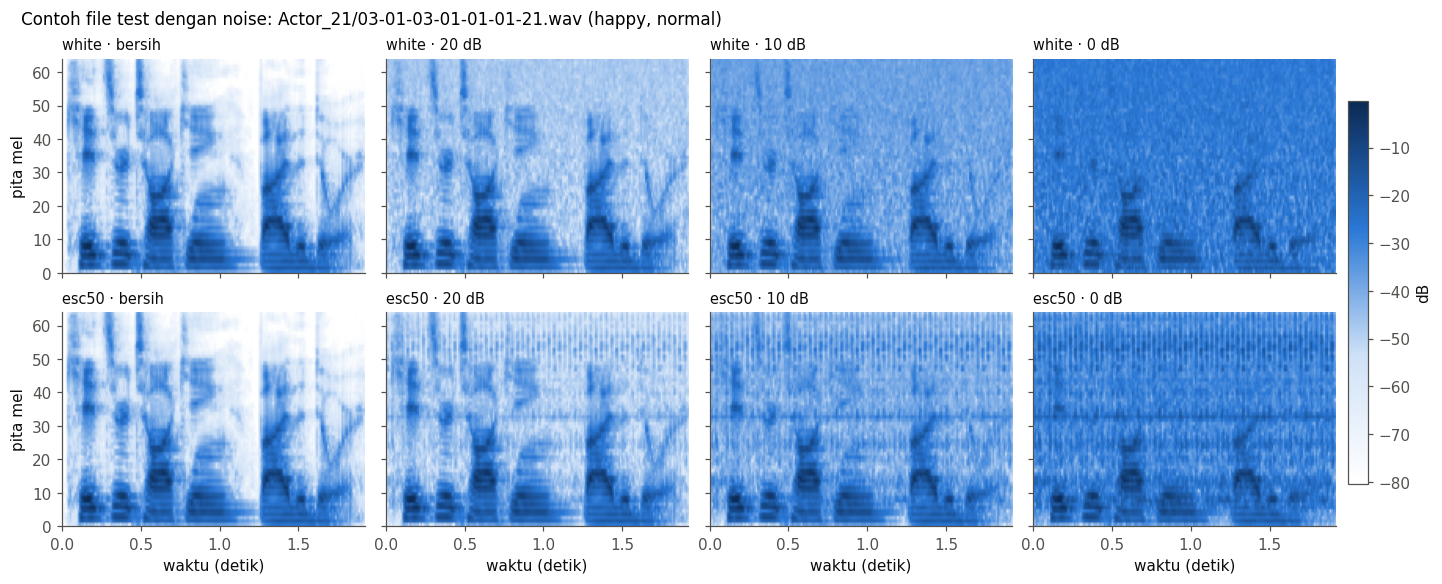

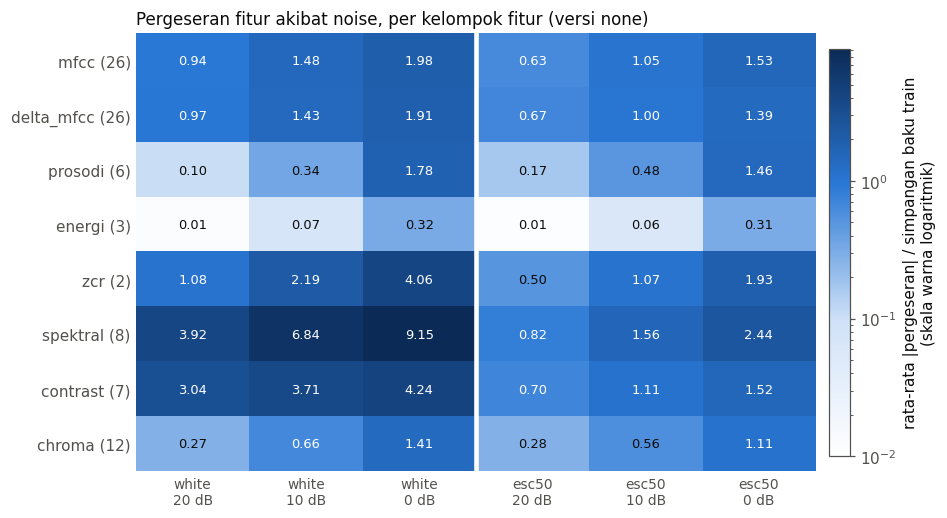

white 0 dB — paling terganggu: flatness_mean (31.70), contrast7_mean (17.03), rolloff_mean (7.50), bandwidth_mean (7.33), zcr_mean (6.73)
white 0 dB — paling tahan   : rms_max (0.06), rms_std (0.26), mfcc04_mean (0.49), mfcc13_mean (0.53), rms_mean (0.63)
esc50 0 dB — paling terganggu: dmfcc01_std (3.54), flatness_mean (3.30), mfcc01_std (3.28), voiced_ratio (3.21), rolloff_std (2.90)
esc50 0 dB — paling tahan   : rms_max (0.14), rms_std (0.21), rms_mean (0.57), mfcc04_mean (0.73), mfcc02_mean (0.73)


In [9]:
CMAP = LinearSegmentedColormap.from_list('biru', ['#ffffff', '#cfe1f7', '#2a78d6', '#0b2a55'])
i_contoh = int(np.flatnonzero(((test_rows['emotion'] == 'happy') & (test_rows['intensity'] == 'normal')).to_numpy())[0])
f_contoh = test_rows['file'][i_contoh]
y0, _ = sf.read(os.path.join(PROC_DIR, f_contoh), dtype='float32')

def mel_db(y):
    M = librosa.feature.melspectrogram(y=y, sr=SR, n_fft=FC['n_fft'], hop_length=FC['hop_length'], n_mels=64)
    return librosa.power_to_db(M, ref=1.0, top_db=None)

ref_db = mel_db(y0).max()
fig, axes = plt.subplots(2, 4, figsize=(13, 5.2), sharex=True, sharey=True, layout='constrained')
for r, j in enumerate(NOISY_CONFIG['noise_types']):
    sumber, offset, seg = rencana_noise(i_contoh, j, len(y0))
    kolom = [('bersih', y0)] + [(f'{s} dB', nz.mix_at_snr(y0, seg, s)[0]) for s in SNRS]
    for c, (judul, y) in enumerate(kolom):
        ax = axes[r, c]
        im = ax.imshow(mel_db(y), origin='lower', aspect='auto', cmap=CMAP, vmin=ref_db - 80, vmax=ref_db,
                       extent=[0, len(y) / SR, 0, 64])
        ax.set_title(f'{j} · {judul}' if c else f'{j} · bersih', loc='left', fontsize=9.5)
        if c == 0:
            ax.set_ylabel('pita mel')
        if r == 1:
            ax.set_xlabel('waktu (detik)')
cb = fig.colorbar(im, ax=axes, fraction=0.015, pad=0.01)
cb.set_label('dB')
fig.suptitle(f'Contoh file test dengan noise: {f_contoh} (happy, normal)', x=0.01, ha='left', fontsize=11)
fig.savefig(os.path.join(FIG_DIR, 'noisy_01_spektrogram.png'))
plt.show()

grp = names.set_index('name')['group']
urut_grp = list(dict.fromkeys(names['group']))
kol = [(j, s) for j in NOISY_CONFIG['noise_types'] for s in SNRS]
H = pd.DataFrame({f'{j}\n{s} dB': DIST[(j, s)].groupby(grp).mean().reindex(urut_grp) for j, s in kol})
fig, ax = plt.subplots(figsize=(8.5, 4.6), layout='constrained')
vmax = max(float(np.nanmax(H.values)), 0.1)
norm = LogNorm(vmin=0.01, vmax=vmax)   # skala log: beda 0,1 / 1 / 10 sama-sama terlihat
im = ax.imshow(np.clip(H.values, 0.01, None), cmap=CMAP, norm=norm, aspect='auto')
ax.set_xticks(range(H.shape[1]))
ax.set_xticklabels(H.columns, fontsize=9)
ax.set_yticks(range(H.shape[0]))
ax.set_yticklabels([f'{g} ({int((grp == g).sum())})' for g in H.index])
ax.axvline(len(SNRS) - 0.5, color='white', lw=3)
for a in range(H.shape[0]):
    for b in range(H.shape[1]):
        v = H.values[a, b]
        ax.text(b, a, f'{v:.2f}', ha='center', va='center', fontsize=8.5,
                color='white' if norm(max(v, 0.01)) > 0.6 else '#0b0b0b')
ax.tick_params(length=0)
for s_ in ax.spines.values():
    s_.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cb.set_label('rata-rata |pergeseran| / simpangan baku train\n(skala warna logaritmik)')
ax.set_title('Pergeseran fitur akibat noise, per kelompok fitur (versi none)', loc='left', fontsize=11)
fig.savefig(os.path.join(FIG_DIR, 'noisy_02_distorsi_fitur.png'))
plt.show()

TOP = {j: DIST[(j, 0)].sort_values(ascending=False) for j in NOISY_CONFIG['noise_types']}
TAHAN = {j: DIST[(j, 0)].sort_values() for j in NOISY_CONFIG['noise_types']}
for j in NOISY_CONFIG['noise_types']:
    print(f'{j} 0 dB — paling terganggu:', ', '.join(f'{n} ({v:.2f})' for n, v in TOP[j].head(5).items()))
    print(f'{j} 0 dB — paling tahan   :', ', '.join(f'{n} ({v:.2f})' for n, v in TAHAN[j].head(5).items()))

## Sel 9 — Ringkasan dan dokumentasi standar

In [10]:
tgl = datetime.now().strftime('%Y-%m-%d')
ringkas = [
    f'Ringkasan test bernoise (langkah 9, {tgl})',
    f"config_hash noisy_test: {NOISY_HASH} | fitur: {CONFIG['features']['config_hash']}",
    '',
    f"Data: test split utama, aktor {S['test']} ({len(test_rows)} file)",
    f"Noise: white dan ESC-50 ({len(ESC_NAMES)} klip, kategori {', '.join(NOISY_CONFIG['esc50_categories'])})",
    f'SNR: {SNRS} dB | versi: none, peak | 12 tabel',
    f'SNR terukur: selisih maksimum {sel.max():.4f} dB dari target',
    '',
    'Rata-rata pergeseran fitur (|selisih| / simpangan baku train, semua 90 fitur):',
] + [f"  {j:<6}: " + ', '.join(f'{s} dB {DIST[(j, s)].mean():.2f}' for s in SNRS) for j in NOISY_CONFIG['noise_types']] + [
    '',
    'Pergeseran per kelompok (kolom: ' + ', '.join(c.replace(chr(10), ' ') for c in H.columns) + '):',
] + [f'  {g:<11} ' + '  '.join(f'{v:.2f}' for v in H.loc[g]) for g in H.index] + [
    '',
] + [f"{j} 0 dB paling terganggu: " + ', '.join(f'{n} ({v:.2f})' for n, v in TOP[j].head(5).items()) for j in NOISY_CONFIG['noise_types']] + [
    f"{j} 0 dB paling tahan   : " + ', '.join(f'{n} ({v:.2f})' for n, v in TAHAN[j].head(5).items()) for j in NOISY_CONFIG['noise_types']] + [
    '',
    'File tanpa frame bersuara: bersih %d | ' % int((test_rows['voiced_ratio'] == 0).sum()) + ', '.join(f'{k}: {v}' for k, v in unv.items()),
    '',
    f'Verifikasi: {n_ok}/{len(laporan)} OK',
] + ['  ' + x for x in laporan]
teks = '\n'.join(ringkas)
print(teks)
with open(os.path.join(FIG_DIR, 'noisy_summary.txt'), 'w', encoding='utf-8') as fh:
    fh.write(teks + '\n')

tabel_h = '| Kelompok | ' + ' | '.join(c.replace('\n', ' ') for c in H.columns) + ' |\n| --- |' + ' --- |' * H.shape[1] + '\n' + \
    '\n'.join(f'| {g} | ' + ' | '.join(f'{v:.2f}' for v in H.loc[g]) + ' |' for g in H.index)
readme = f'''# Langkah 9 — Test Bernoise

Penanggung jawab: Anggota A · Versi: 1.0 · Dijalankan: {tgl} · config_hash: `{NOISY_HASH}` (fitur `{CONFIG['features']['config_hash']}`)

## Tujuan

Menyediakan versi bernoise dari test split utama (aktor {', '.join(map(str, S['test']))}) pada SNR 20, 10, dan 0 dB, untuk menguji ketahanan model dan subset fitur hasil SA (failure experiment tambahan). Tidak ada model yang dilatih atau dievaluasi di langkah ini.

## Rancangan

| Komponen | Pilihan |
| --- | --- |
| Jenis noise | `white` (Gaussian) dan `esc50` ({len(ESC_NAMES)} klip ESC-50: {', '.join(NOISY_CONFIG['esc50_categories'])}) |
| SNR | 20, 10, 0 dB, terhadap daya ucapan hasil trim |
| Titik penambahan | Setelah preprocessing (trim), sebelum ekstraksi fitur; trim tidak diulang |
| Potongan noise | Sama untuk ketiga SNR pada file yang sama; dipilih deterministik dengan seed {NOISY_CONFIG['seed']} |
| Fitur | 90 fitur dengan `src/features.py`, versi `none` dan `peak` |

## Output

| File | Isi |
| --- | --- |
| `data/features/noisy/test_noisy_{{white,esc50}}_{{20,10,0}}db_{{none,peak}}.csv` | 12 tabel, masing-masing {len(test_rows)} baris, kolom sama dengan `features_none.csv` |
| `data/features/noisy/noisy_log.csv` | Per campuran: file, jenis noise, klip sumber, offset, SNR target dan terukur, faktor pengali |
| `data/features/noisy/noisy_meta.json` | config_hash, jumlah file, daftar tabel |
| `src/noise.py` | `white_noise`, `fit_length`, `mix_at_snr`, `measure_snr`, `clean_noise_clip` |
| `figures/noisy/` | `noisy_01_spektrogram.png`, `noisy_02_distorsi_fitur.png`, `noisy_summary.txt` |

## Cara memakai (Anggota C)

```python
import pandas as pd
names = pd.read_csv(BASE_DIR + '/data/features/feature_names.csv')
te_noisy = pd.read_csv(BASE_DIR + '/data/features/noisy/test_noisy_esc50_10db_none.csv')
X_te_noisy = te_noisy[names['name']].values   # urutan baris sama dengan test bersih
y_te = te_noisy['emotion'].values
# model dilatih di train bersih (dan dipilih di validation bersih), lalu dievaluasi di tabel ini
```

Pakai versi (`none` atau `peak`) yang sama dengan pilihan baseline Anggota B.

## Pergeseran fitur akibat noise

Rata-rata |fitur bernoise − fitur bersih| dibagi simpangan baku fitur di data train (versi none):

{tabel_h}

## Verifikasi

{n_ok}/{len(laporan)} pemeriksaan OK.

''' + '\n'.join(f'- {x}' for x in laporan) + f'''

## Keterbatasan

- Noise ditambahkan secara digital setelah trim. Di rekaman nyata, noise juga memengaruhi trim (hening di awal dan akhir tidak terbuang), sehingga kondisi nyata bisa lebih berat.
- Noise bersifat aditif saja; tidak ada gema ruangan (reverberation) atau distorsi mikrofon.
- ESC-50 berlisensi CC BY-NC 3.0 (Piczak, 2015); klip tidak disimpan di repo, hanya daftar nama klip di `noisy_log.csv`.

## Riwayat versi

| Versi | Tanggal | Perubahan |
| --- | --- | --- |
| 1.0 | {tgl} | Versi pertama |
'''
with open(os.path.join(DOC_DIR, 'README_langkah9_test_bernoise.md'), 'w', encoding='utf-8') as fh:
    fh.write(readme)
print('\nTersimpan:', os.path.join(FIG_DIR, 'noisy_summary.txt'))
print('Tersimpan:', os.path.join(DOC_DIR, 'README_langkah9_test_bernoise.md'))

Ringkasan test bernoise (langkah 9, 2026-11-21)
config_hash noisy_test: dcf3a82fad | fitur: 0c3114fc78

Data: test split utama, aktor [21, 22, 23, 24] (240 file)
Noise: white dan ESC-50 (240 klip, kategori rain, wind, vacuum_cleaner, washing_machine, engine, keyboard_typing)
SNR: [20, 10, 0] dB | versi: none, peak | 12 tabel
SNR terukur: selisih maksimum 0.0000 dB dari target

Rata-rata pergeseran fitur (|selisih| / simpangan baku train, semua 90 fitur):
  white : 20 dB 1.20, 10 dB 1.90, 0 dB 2.67
  esc50 : 20 dB 0.56, 10 dB 0.95, 0 dB 1.48

Pergeseran per kelompok (kolom: white 20 dB, white 10 dB, white 0 dB, esc50 20 dB, esc50 10 dB, esc50 0 dB):
  mfcc        0.94  1.48  1.98  0.63  1.05  1.53
  delta_mfcc  0.97  1.43  1.91  0.67  1.00  1.39
  prosodi     0.10  0.34  1.78  0.17  0.48  1.46
  energi      0.01  0.07  0.32  0.01  0.06  0.31
  zcr         1.08  2.19  4.06  0.50  1.07  1.93
  spektral    3.92  6.84  9.15  0.82  1.56  2.44
  contrast    3.04  3.71  4.24  0.70  1.11  1.52


## Selesai — yang dilakukan setelah notebook ini

1. Pastikan semua uji di Sel 4 dan verifikasi di Sel 7 bertanda **OK**.
2. Simpan notebook ke `project07/notebooks/Langkah9_AnggotaA_Test_Bernoise.ipynb`.
3. Kirim ke saya untuk Log Kerja: isi `noisy_summary.txt` serta screenshot grafik `noisy_01` dan `noisy_02`.
4. Folder `data/raw/esc50/` tidak di-push (sudah tercakup aturan `data/raw/` di `.gitignore`). Folder `data/features/noisy/` (±5 MB) di-push.